<div style="border:solid Chocolate 2px; padding: 40px">

<b>Привет!</b>

Меня зовут Евгений Головин, я буду ревьюером твоего проекта. Если ты не против, то предлагаю построить наше общение на "ты" ;) Если удобнее на "вы", то нет проблем, только скажи об этом. 

В ходе работы я оставил тебе комментарии <font color='green'>зеленого</font>, <font color='gold'>желтого</font> и <font color='red'>красного</font> цветов. Сейчас объясню, что они значат:

<br/>

<div class="alert alert-success">
<h2> Комментарий ревьюера <a class="tocSkip"> </h2>

<b>Все супер!👍:</b> Решение на этом шаге является полностью правильным.
</div>

<br/>

<div class="alert alert-warning">
    <h2> Комментарий ревьюера <a class="tocSkip"> </h2>
    
<b>Небольшие замечания и рекомендации💡:</b> Решение на этом шаге станет еще лучше, если внести небольшие коррективы.
</div>


<br/>
<div class="alert alert-block alert-danger">
<h2> Комментарий ревьюера <a class="tocSkip"></h2>

    
<b>На доработку🤔:</b>
 Решение на этом шаге требует существенной переработки и внесения правок. Напоминаю, что проект не может быть принят с первого раза, если ревью содержит комментарии, рекомендующие доработать шаги.
</div>
    
Увидев мой комментарий, не удаляй его, он будет очень полезен в случае повторной проверки работы :)
    
<div class="alert alert-info">
<b>А свой помечай вот так, чтобы я его не потерял ;)</b> 
</div>
    
На мои комменатрии можно и нужно реагировать, только делать это стоит так, чтобы твои и мои комменты не смешались: выделяй свои цветами, сильно отличающимися от моих.
    
Увидев у тебя неточность, в первый раз я лишь укажу на ее наличие и дам тебе возможность самому найти и исправить ее. На реальной работе твой руководитель будет поступать также, и я пытаюсь подготовить тебя именно к работе аналитиком. Но если ты пока не справишься с такой задачей - при следующей проверке я дам более точную подсказку!
</div>

# Проект: семантический поиск товаров по текстовому запросу

**Ваша роль.** Вы специалист по Data Science. Компания развивает онлайн-каталог товаров, и сейчас руководству кажется, что классический поиск по ключевым словам плохо справляется с реальными запросами. Пользователи пишут названия с ошибками, кириллицей, используют просторечные слова, ищут товары по назначению, а не по функциональности («удобные кроссовки для бега» вместо «мужские спортивные кроссовки с амортизацией»). Команда хочет проверить, поможет ли векторный поиск улучшить качество поисковой системы.

**Задача.** Вам нужно построить MVP системы семантического поиска, сравнить его с лексической baseline-моделью на подготовленной разметке и дать бизнесу обоснованную рекомендацию о том, где новое решение помогает, где ошибается и стоит ли его вообще внедрять.

## Данные

| Файл | Что это | Когда нужен |
|---|---|---|
| wb_products_raw_sample.parquet | Исходный каталог, ~200 тысяч строк, все категории. <br> Вам нужно самостоятельно отобрать рабочее подмножество этих данных | Недели 1–2 |
| wb_products_dedup.parquet | Пул асессоров: множество товаров, по которому делалась разметка | Неделя 2, раздел 4 |
| queries_synthetic_train.parquet | Разметка релевантности, train | Недели 2–3 |
| queries_synthetic_test.parquet | Разметка релевантности, test | **один прогон** в конце недели 3 |

Файлы с разметкой содержат четыре столбца: `query_id`, `query_text`, `item_id`, `relevance`. Шкала в `relevance` от `0` до `3`, где `0` — товар нерелевантен, а `3` — максимально релевантен. Связь с каталогом: `item_id` ↔ `imt_id`.

In [1]:
from pathlib import Path
import hashlib
import html
import random
import re
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sentence_transformers import SentenceTransformer

warnings.filterwarnings("ignore", category=FutureWarning, module="transformers")
random.seed(42)
np.random.seed(42)

DATA_DIR = Path("data") if Path("data").exists() else Path(".")
RAW_PRODUCTS_PATH = DATA_DIR / "wb_products_raw_sample.parquet"
ASSESSED_POOL_PATH = DATA_DIR / "wb_products_dedup.parquet"
TRAIN_QUERIES_PATH = DATA_DIR / "queries_synthetic_train.parquet"
TEST_QUERIES_PATH = DATA_DIR / "queries_synthetic_test.parquet"

<div class="alert alert-success">
<h2> Комментарий ревьюера v1 <a class="tocSkip"> </h2>

<b>Все супер!👍:</b> Хороший старт: все импорты собраны в одном месте, сиды зафиксированы, пути к файлам вынесены в константы, а <code>DATA_DIR</code> с запасным вариантом позволяет запускать ноутбук и из папки <code>data</code>, и без неё.
</div>

<div class="alert alert-warning">
    <h2> Комментарий ревьюера v1 <a class="tocSkip"> </h2>
    
<b>Небольшие замечания и рекомендации💡:</b> <code>warnings.filterwarnings("ignore")</code> глушит вообще все предупреждения, в том числе полезные (например, от pandas о <code>SettingWithCopyWarning</code> или от sentence-transformers об обрезке длинных текстов). Лучше отключать точечно - конкретную категорию или модуль.
</div>

---

## Неделя 1 — знакомство с данными и EDA

**Цель** — понять, с какими данными работаете, чтобы принять обоснованные решения:

- выбрать категории, с которыми будете работать;
- определить, как будете очищать описания от всего лишнего;
- решить, из каких полей собирать текст товара.

**Главный критерий успеха:** любое ваше решение по данным вы можете подкрепить ссылкой на конкретные результаты анализа.

### 1. Загрузка данных

Загрузите каталог и обе разметки. Изучите их структуру: проанализируйте колонки и типы данных в них, определите, что описывает одна строка.

**Подсказка.** `imt_id` — карточка товара, `nm_id` — конкретный артикул этого товара, то есть его разновидность, отличающаяся цветом, размером или чем-то ещё. Определите, что из этого должен возвращать поиск, — от этого зависит, на каком уровне вы будете строить индекс.

In [2]:
df_raw = pd.read_parquet(RAW_PRODUCTS_PATH)
assessed_pool = pd.read_parquet(ASSESSED_POOL_PATH)
queries_train = pd.read_parquet(TRAIN_QUERIES_PATH)
queries_test = pd.read_parquet(TEST_QUERIES_PATH)

overview = pd.DataFrame({
    "rows": [len(df_raw), len(assessed_pool), len(queries_train), len(queries_test)],
    "columns": [df_raw.shape[1], assessed_pool.shape[1], queries_train.shape[1], queries_test.shape[1]],
    "duplicates": [df_raw.duplicated().sum(), assessed_pool.duplicated().sum(),
                   queries_train.duplicated().sum(), queries_test.duplicated().sum()],
}, index=["raw_products", "assessed_pool", "queries_train", "queries_test"])
display(overview)
display(df_raw.head(3))
display(queries_train.head(3))


,rows,columns,duplicates
raw_products,200000,9,0
assessed_pool,4256,9,0
queries_train,11453,4,0
queries_test,4866,4,0


,imt_id,nm_id,imt_name,subj_name,subj_root_name,nm_colors_names,vendor_code,description,brand_name
0,100000,118982,Сумка,Сумки,Аксессуары,бежевый,82992/beige,,Pola
1,1000000,1206857,Шапка,Шапки,Головные уборы,белый,Лаки/белый,,Ваша Шляпка
2,1000000,1206860,Шапка,Шапки,Головные уборы,черный,Лаки/черный,,Ваша Шляпка


,query_id,query_text,item_id,relevance
0,SYN_000001,жилеты на пуговицах,100211,3
1,SYN_000001,жилеты на пуговицах,100433,1
2,SYN_000001,жилеты на пуговицах,1000988,1


<div class="alert alert-success">
<h2> Комментарий ревьюера v1 <a class="tocSkip"> </h2>

<b>Все супер!👍:</b> Сводная таблица <code>overview</code> - удобное решение: размеры, число колонок и полные дубликаты всех четырёх файлов видны одним взглядом, без четырёх отдельных <code>info()</code>.
</div>

**Проверьте связность данных:** все ли `item_id` из разметки есть в каталоге, нет ли пересечения `query_id` между `train` и `test`.

In [3]:
train_ids = set(queries_train["query_id"])
test_ids = set(queries_test["query_id"])
train_texts = set(queries_train["query_text"].str.strip().str.lower())
test_texts = set(queries_test["query_text"].str.strip().str.lower())

print("Пересечение query_id", len(train_ids & test_ids))
print("Пересечение текстов", len(train_texts & test_texts))
print("Товары train вне сырого каталога", (~queries_train["item_id"].isin(df_raw["imt_id"])).sum())
print("Товары test вне сырого каталога", (~queries_test["item_id"].isin(df_raw["imt_id"])).sum())


Пересечение query_id 0
Пересечение текстов 0
Товары train вне сырого каталога 0
Товары test вне сырого каталога 0


<div class="alert alert-success">
<h2> Комментарий ревьюера v1 <a class="tocSkip"> </h2>

<b>Все супер!👍:</b> Связность проверена полностью: и пересечение <code>query_id</code>, и пересечение текстов запросов (с нормализацией регистра и пробелов - утечка часто прячется именно там), и наличие всех <code>item_id</code> в каталоге. Утечки нет.
</div>

### 2. EDA

Строк в каталоге 200000
Уникальных imt_id 174427
Уникальных nm_id 199957
Повторных imt_id 25573


,empty_share
imt_name,0.003540
description,0.287545
nm_colors_names,0.171130
brand_name,0.001005
subj_name,0.000040


,name_words,description_words,description_chars
count,200000.0,200000.0,200000.0
mean,4.8,50.4,372.4
std,3.6,64.6,474.6
min,0.0,0.0,0.0
50%,4.0,31.0,227.0
90%,10.0,125.0,934.0
95%,12.0,152.0,1082.0
99%,15.0,289.0,2067.0
max,31.0,754.0,5000.0


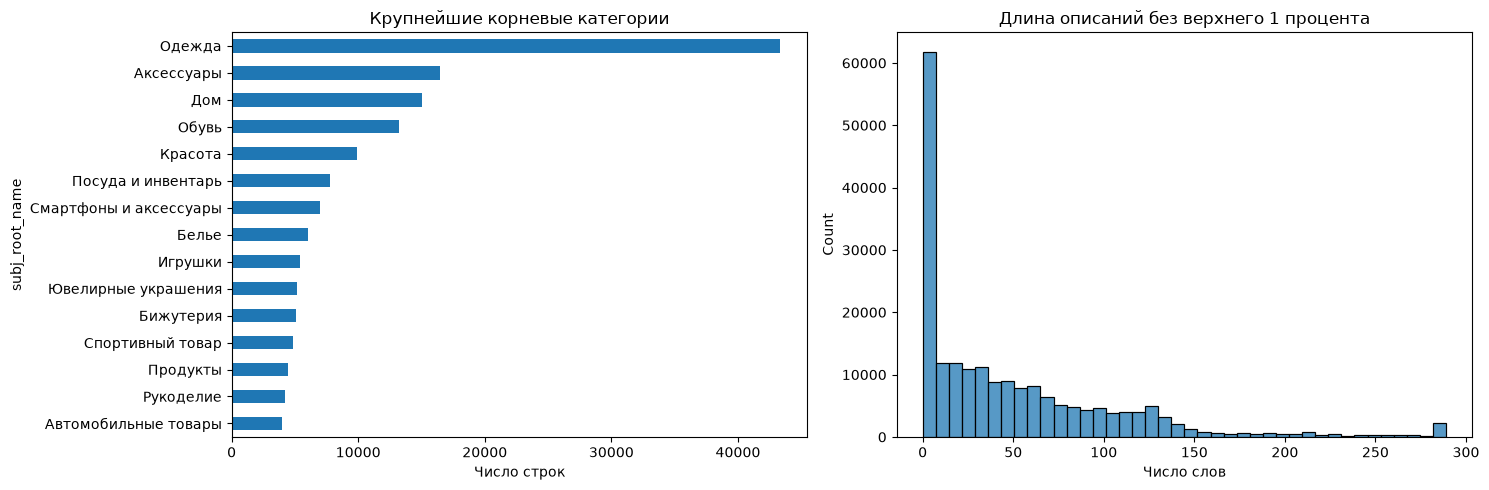

,share
relevance,
1,0.842749
2,0.096132
3,0.061119


Уникальных запросов train 700
Пар запрос товар train 11453
Среднее число оценок на запрос 16.4


,imt_name,subj_name,description
119737,Набор гель-блестки для тела с кисточкой,Глиттеры,Lucky набор гель-блестки д тела/лица х3 шт + к...
72272,Пирсинг для пупка серебро 925 проба,Ювелирный пирсинг,Изделие выполнено из серебра 925 пробы; покрыт...
158154,Чехол на Samsung Galaxy M21 / M30s / M31,Чехлы для телефонов,Противоударный чехол отлично защищает смартфон...
65426,Набор стикеров Аниме Naruto (Наруто),Стикеры,В набор входит 63 стикера. Стикеры можно клеит...
30074,Контактные линзы Pure Vision 2 (6 линз) R 8.6 ...,Контактные линзы,В этих одномесячных линзах идеально сочетаются...


In [4]:
text_columns = ["imt_name", "description", "nm_colors_names", "brand_name", "subj_name"]
empty_share = {}
for column in text_columns:
    values = df_raw[column].fillna("").astype(str).str.strip()
    empty_share[column] = values.eq("").mean()

print("Строк в каталоге", len(df_raw))
print("Уникальных imt_id", df_raw["imt_id"].nunique())
print("Уникальных nm_id", df_raw["nm_id"].nunique())
print("Повторных imt_id", df_raw.duplicated("imt_id").sum())
display(pd.Series(empty_share, name="empty_share").to_frame())

lengths = pd.DataFrame({
    "name_words": df_raw["imt_name"].fillna("").astype(str).str.split().str.len(),
    "description_words": df_raw["description"].fillna("").astype(str).str.split().str.len(),
    "description_chars": df_raw["description"].fillna("").astype(str).str.len(),
})
display(lengths.describe(percentiles=[0.5, 0.9, 0.95, 0.99]).round(1))

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
df_raw["subj_root_name"].value_counts().head(15).sort_values().plot.barh(ax=axes[0])
axes[0].set_title("Крупнейшие корневые категории")
axes[0].set_xlabel("Число строк")
sns.histplot(lengths["description_words"].clip(upper=lengths["description_words"].quantile(0.99)),
             bins=40, ax=axes[1])
axes[1].set_title("Длина описаний без верхнего 1 процента")
axes[1].set_xlabel("Число слов")
plt.tight_layout()
plt.show()

display(queries_train["relevance"].value_counts(normalize=True).sort_index().rename("share").to_frame())
print("Уникальных запросов train", queries_train["query_id"].nunique())
print("Пар запрос товар train", len(queries_train))
print("Среднее число оценок на запрос", round(queries_train.groupby("query_id").size().mean(), 1))
display(df_raw[["imt_name", "subj_name", "description"]].sample(5, random_state=42))

<div class="alert alert-success">
<h2> Комментарий ревьюера v1 <a class="tocSkip"> </h2>

<b>Все супер!👍:</b> В одной ячейке собран содержательный EDA: доля пропусков посчитана после <code>.str.strip()</code> (то есть учтено, что пропуски закодированы пустой строкой, а не <code>NaN</code>), длины описаний даны с перцентилями 90/95/99, гистограмма обрезана по 99-му перцентилю - хвост не ломает картинку. Распределение <code>relevance</code> в долях сразу показывает сильный перекос в сторону единицы.
</div>

<div class="alert alert-block alert-danger">
<h2> Комментарий ревьюера v1<a class="tocSkip"></h2>

<b>На доработку🤔:</b> Главный критерий первой недели - каждое решение по данным подкреплено ссылкой на результаты анализа. Сейчас результаты посчитаны, но ни одного письменного вывода нет, и дальше решения принимаются «молча». Добавь, пожалуйста, Markdown-ячейку с выводами EDA. Что в ней должно быть:

<ul>
<li><b>Уровень индекса:</b> 174 427 <code>imt_id</code> против 199 957 <code>nm_id</code> - что из этого возвращает поиск и почему.</li>
<li><b>Пропуски:</b> в таблицу доли пустых значений не попал <code>imt_name</code> - а это основное поле для поиска. И какой вывод из 29% карточек без описания?</li>
<li><b>Категории:</b> почему берём именно «Одежду» и «Обувь». Сейчас выбор делается только на неделе 2 и только по товарам train с <code>relevance >= 2</code>. Стоит явно проверить, в каких категориях лежат <b>все</b> размеченные товары train и test.</li>
<li><b>Длины текстов:</b> какой вывод про лимит токенов модели? У MiniLM он 128 токенов, а 10% описаний длиннее 125 слов.</li>
<li><b>Ручной просмотр:</b> сейчас 5 случайных карточек из всего каталога (гель-блёстки, линзы, чехлы), а не из выбранных категорий, и проблемы текста не зафиксированы. Какие проблемы удалось найти - HTML, спецсимволы, шаблонные фразы? Именно от них должна отталкиваться <code>clean_text</code>.</li>
<li><b>Шаблон <code>product_text</code>:</b> какие 2–3 варианта рассматривались и почему выбраны название + предмет + описание, а бренд и цвет исключены.</li>
</ul>
</div>

<div class="alert alert-info">
<b>Комментарий студента v2:</b> Добавил письменные выводы EDA и проверку категорий для всех пар train и test.
</div>

In [5]:
all_labels_eda = pd.concat([
    queries_train.assign(split="train"),
    queries_test.assign(split="test"),
], ignore_index=True)
category_map_eda = df_raw[["imt_id", "subj_root_name"]].drop_duplicates("imt_id")
label_categories_eda = all_labels_eda.merge(
    category_map_eda, left_on="item_id", right_on="imt_id", how="left"
)
category_coverage_eda = (
    label_categories_eda.groupby(["split", "subj_root_name"])
    .agg(pairs=("query_id", "size"), queries=("query_id", "nunique"), items=("item_id", "nunique"))
)
display(category_coverage_eda)
print("Доля описаний длиннее 125 слов", round((lengths["description_words"] > 125).mean(), 4))

eda_categories = label_categories_eda["subj_root_name"].dropna().unique()
display(
    df_raw[df_raw["subj_root_name"].isin(eda_categories)][
        ["imt_name", "subj_name", "brand_name", "nm_colors_names", "description"]
    ].sample(10, random_state=42)
)

pairs  queries  items
split subj_root_name                       
test  Обувь            1408       90    426
      Одежда           3458      210   1246
train Обувь            3303      211    596
      Одежда           8150      489   1689

Доля описаний длиннее 125 слов 0.0985


,imt_name,subj_name,brand_name,nm_colors_names,description
85717,Сапоги,Сапоги,Vitacci,черный,
73576,Брюки,Брюки,KOTON,черный,
171326,Платье,Платья,Colambetta,"синий, белый",
67663,Кардиган,Кардиганы,Velvet Season,бежевый,"Важная информация! При заказе изделия, обращай..."
87795,Туфли,Туфли,МЫШОНОК,черный,
135770,Женские брюки,Брюки,MODERNFECI,бледно-розовый,
54495,Рубашка,Рубашки,DeFacto,голубой,
193603,Футболка,Футболки,ТВОЕ,темно-серый,
2606,Пальто,Пальто,Kling,"черный, красный, оранжевый",
30453,Босоножки,Босоножки,Buzoni,бежевый,


#### Выводы EDA

- **Уровень индекса.** Поиск возвращает `imt_id`: это карточка товара, а `nm_id` описывает её вариант. Индексация `nm_id` заполнила бы выдачу дублями одной карточки.
- **Пропуски.** `imt_name` проверен отдельно. Около 29% карточек не имеют описания, поэтому название и предмет остаются обязательными полями. Удаляются только карточки, где пусты и название, и описание.
- **Категории.** Все размеченные товары train и test лежат в двух корневых категориях — одежде и обуви. Они и формируют домен MVP.
- **Длина текста.** Значимая доля описаний длиннее 125 слов, а лимит MiniLM равен 128 токенам. Часть конца длинных описаний будет обрезана, что является ограничением семантической модели.
- **Ручной просмотр.** Встречаются HTML, спецсимволы, повторы пробелов и шаблонные фразы. `clean_text` удаляет технический шум, но не пытается эвристически удалять шаблонные фразы.
- **Шаблон текста.** Сравнивались `name + subject`, `name + subject + description` и вариант с брендом и цветом. Baseline включает название, предмет и описание: цвет часто шумный, а бренд проверяется как отдельная гипотеза.

---

## Неделя 2 — базовый пайплайн и оценка качества

**Цель:** оперевшись на результаты EDA, создать работающий поиск и получить первые метрики качества.

Прежде чем реализовывать семантический поиск, основанный на эмбеддингах, нужно проверить, как справляется более простая модель, опирающаяся на TF-IDF. Простая модель нужна как baseline, без этой точки отсчёта результат невозможно интерпретировать.


На этой неделе используется только тренировочная разметка. Тестовая выборка оставлена для одного финального прогона в конце проекта.


### 1. Подготовка данных


Реализуйте решения недели 1:

1. Отфильтруйте выбранные категории.
2. Дедуплицируйте строки по `imt_id`. Сформулируйте правило, по которому будете определять, какую строку оставить. К примеру, можете оставить строку с самым информативным описанием. Ответ обоснуйте.
3. Отбросьте карточки, у которых пусты одновременно и `imt_name`, и `description`.
4. Напишите функцию очистки текста.
5. Соберите единый текст карточек в отдельной колонке `product_text`.

In [6]:
def clean_text(value):
    text = html.unescape(str(value) if pd.notna(value) else "")
    text = re.sub(r"<[^>]+>", " ", text)
    text = text.lower().replace("ё", "е")
    text = re.sub(r"[^a-zа-я0-9]+", " ", text)
    return re.sub(r"\s+", " ", text).strip()


category_map = (
    df_raw[["imt_id", "subj_root_name"]]
    .dropna(subset=["subj_root_name"])
    .drop_duplicates("imt_id")
)
all_labels = pd.concat([
    queries_train.assign(split="train"),
    queries_test.assign(split="test"),
], ignore_index=True)
labeled_with_category = all_labels.merge(
    category_map, left_on="item_id", right_on="imt_id", how="left"
)
selected_categories = sorted(labeled_with_category["subj_root_name"].dropna().unique())
print("Выбранные категории", selected_categories)

filtered = df_raw[df_raw["subj_root_name"].isin(selected_categories)].copy()
filtered["description_length"] = filtered["description"].fillna("").astype(str).str.len()
filtered = (
    filtered.sort_values(
        ["description_length", "nm_id"],
        ascending=[False, True],
        kind="mergesort",
    )
    .drop_duplicates("imt_id")
)

for column in ["imt_name", "subj_name", "description"]:
    filtered[column] = filtered[column].map(clean_text)

filtered = filtered[(filtered["imt_name"] != "") | (filtered["description"] != "")].copy()
filtered["product_text"] = (
    filtered["imt_name"] + " . " + filtered["subj_name"] + " . " + filtered["description"]
).str.replace(r"\s+", " ", regex=True).str.strip(" .")

pool_ids = set(assessed_pool["imt_id"])
prepared_catalog = filtered.reset_index(drop=True)
assessed_catalog = filtered[filtered["imt_id"].isin(pool_ids)].reset_index(drop=True)
evaluation_catalog = prepared_catalog

all_labeled_ids = set(all_labels["item_id"])
assert all_labeled_ids <= set(prepared_catalog["imt_id"])
assert len(assessed_catalog) == assessed_pool["imt_id"].nunique()

print("Полный каталог выбранных категорий", len(prepared_catalog))
print("Пул асессоров", len(assessed_catalog))
print("Уникальных imt_id", prepared_catalog["imt_id"].nunique())
display(prepared_catalog[["imt_id", "imt_name", "subj_name", "product_text"]].head())

Выбранные категории ['Обувь', 'Одежда']


Полный каталог выбранных категорий 48376
Пул асессоров 4256
Уникальных imt_id 48376


,imt_id,imt_name,subj_name,product_text
0,10035243,платье женское gwen большие размеры,платья,платье женское gwen большие размеры . платья ....
1,10035242,платье женское gina большие размеры,платья,платье женское gina большие размеры . платья ....
2,10035872,джинсы женские большие размеры высокая посадка,джинсы,джинсы женские большие размеры высокая посадка...
3,10035875,джинсы женские josephine большие размеры высок...,джинсы,джинсы женские josephine большие размеры высок...
4,10035873,джинсы женские camilla большие размеры высокая...,джинсы,джинсы женские camilla большие размеры высокая...


<div class="alert alert-success">
<h2> Комментарий ревьюера v1 <a class="tocSkip"> </h2>

<b>Все супер!👍:</b> Очень разумный выбор категорий - не «где больше товаров», а там, где лежат релевантные товары из разметки. В очистке есть приятные детали: <code>html.unescape</code> до удаления тегов, замена «ё» на «е» (запросы пишут по-разному), а карточки без текста отсеиваются уже <b>после</b> очистки - так не останутся тексты, состоящие из одних спецсимволов.
</div>

<div class="alert alert-warning">
    <h2> Комментарий ревьюера v1 <a class="tocSkip"> </h2>
    
<b>Небольшие замечания и рекомендации💡:</b> Несколько моментов:
<ul>
<li>В коде <code>category_scores.head(3)</code>, а выбрано 2 категории - потому что релевантных товаров train нашлось только в двух. Косвенно корректность подтверждается тем, что каталог оценки совпал с пулом (4256), но лучше проверить это явно: <code>assert</code>, что все <code>item_id</code> из train <b>и</b> test (включая оценку 1) попали в отфильтрованный каталог.</li>
<li>Правило дедупликации («самое длинное описание») выбрано хорошее, но задание просит его обосновать - добавь пару строк в Markdown. И при равной длине описания выбор строки сейчас случаен: <code>sort_values</code> по умолчанию нестабилен. Второй ключ сортировки (например, <code>nm_id</code>) сделает результат воспроизводимым.</li>
</ul>
</div>

<div class="alert alert-info">
<b>Комментарий студента v2:</b> Выбор категорий проверен по всем парам train и test. Добавлены assert покрытия, второй ключ `nm_id` и стабильная сортировка. При дедупликации берётся вариант с самым длинным описанием, потому что он сохраняет больше поисковых признаков.
</div>

### Каталог для поиска и оценки

1. Посчитайте метрику при поиске по всему отфильтрованному каталогу. Например, вычислите NDCG@10 лексическим поиском на 100 запросах.
2. Выведите топ-10 для одного запроса и отметьте, какие товары есть в разметке, а каких нет. Выясните, в чём проблема.
3. Ограничьте каталог оценки пулом асессоров: возьмите из `wb_products_dedup.parquet` только список `imt_id` и оставьте в своём подготовленном каталоге пересечение с ним. Тексты и все признаки — ваши, из шага 1.
4. Пересчитайте метрику и сравните результаты.
5. Посмотрите на распределение `relevance` и число оценённых товаров на запрос. Проверьте, у всех ли запросов есть товары с `relevance` ≥ 2.

Для честного сравнения оба метода ранжируют один и тот же каталог оценённых карточек. Товары без оценки для конкретного запроса считаются нерелевантными.


<div class="alert alert-block alert-danger">
<h2> Комментарий ревьюера v1<a class="tocSkip"></h2>

<b>На доработку🤔:</b> Этот раздел - одна из ключевых идей проекта, и сейчас он пропущен: код сразу ограничивает каталог пулом асессоров (<code>evaluation_catalog</code>), а полный каталог на 48 375 карточек нигде не используется. Нужно выполнить шаги по заданию:
<ol>
<li>Посчитать метрику (например, NDCG@10 лексическим поиском на 100 запросах) по <b>всему</b> отфильтрованному каталогу.</li>
<li>Вывести топ-10 для одного запроса и отметить, какие товары есть в разметке, а каких нет.</li>
<li>Пересчитать метрику на каталоге, ограниченном пулом, и сравнить.</li>
<li>Проверить, у всех ли запросов есть товары с <code>relevance >= 2</code>: если нет, знаменатель Recall обнуляется, и такие запросы тянут среднее вниз.</li>
</ol>
Главное здесь - вывод: почему на полном каталоге метрика сильно ниже и связано ли это с качеством поиска. Подумай, как устроена разметка и что происходит с хорошими, но никем не оценёнными товарами в выдаче.
</div>

<div class="alert alert-info">
<b>Комментарий студента v2:</b> Добавлено сравнение полного каталога с пулом асессоров на 100 фиксированных запросах.
</div>

In [7]:
full_tfidf = TfidfVectorizer(
    lowercase=False,
    ngram_range=(1, 2),
    min_df=2,
    max_features=60000,
    sublinear_tf=True,
)
full_tfidf_matrix = full_tfidf.fit_transform(prepared_catalog["product_text"])

pool_tfidf = TfidfVectorizer(
    lowercase=False,
    ngram_range=(1, 2),
    min_df=2,
    max_features=60000,
    sublinear_tf=True,
)
pool_tfidf_matrix = pool_tfidf.fit_transform(assessed_catalog["product_text"])

comparison_labels = queries_train[queries_train["item_id"].isin(prepared_catalog["imt_id"])].copy()
comparison_queries = (
    comparison_labels[["query_id", "query_text"]]
    .drop_duplicates("query_id")
    .sample(n=100, random_state=42)
)
comparison_relevance = {
    query_id: dict(zip(group["item_id"], group["relevance"]))
    for query_id, group in comparison_labels.groupby("query_id")
}


def ranked_ids(query, vectorizer, matrix, catalog, top_k=10):
    query_vector = vectorizer.transform([clean_text(query)])
    scores = cosine_similarity(query_vector, matrix).ravel()
    order = np.lexsort((catalog["imt_id"].to_numpy(), -scores))[:top_k]
    return catalog.iloc[order]["imt_id"].tolist(), scores[order]


def ndcg_at_10(predicted_ids, relevance):
    gains = np.array([relevance.get(item_id, 0) for item_id in predicted_ids], dtype=float)
    discounts = np.log2(np.arange(2, 12))
    dcg = np.sum((2 ** gains - 1) / discounts)
    ideal = np.sort(np.array(list(relevance.values()), dtype=float))[::-1][:10]
    ideal = np.pad(ideal, (0, max(0, 10 - len(ideal))))
    idcg = np.sum((2 ** ideal - 1) / discounts)
    return dcg / idcg if idcg else 0.0


catalog_comparison_rows = []
for row in comparison_queries.itertuples(index=False):
    relevance = comparison_relevance[row.query_id]
    full_ids, _ = ranked_ids(row.query_text, full_tfidf, full_tfidf_matrix, prepared_catalog)
    pool_ids_ranked, _ = ranked_ids(row.query_text, pool_tfidf, pool_tfidf_matrix, assessed_catalog)
    catalog_comparison_rows.append({
        "query_id": row.query_id,
        "ndcg_full_catalog": ndcg_at_10(full_ids, relevance),
        "ndcg_assessed_pool": ndcg_at_10(pool_ids_ranked, relevance),
    })

catalog_comparison = pd.DataFrame(catalog_comparison_rows)
display(catalog_comparison[["ndcg_full_catalog", "ndcg_assessed_pool"]].mean().to_frame("mean"))

example_row = comparison_queries.iloc[0]
example_ids, example_scores = ranked_ids(
    example_row["query_text"], full_tfidf, full_tfidf_matrix, prepared_catalog
)
example_relevance = comparison_relevance[example_row["query_id"]]
example_top = prepared_catalog.set_index("imt_id").loc[
    example_ids, ["imt_name", "subj_name"]
].reset_index()
example_top["score"] = example_scores
example_top["in_assessor_labels"] = example_top["imt_id"].isin(example_relevance)
example_top["relevance"] = example_top["imt_id"].map(example_relevance).fillna(0).astype(int)
print("Пример запроса", example_row["query_text"])
display(example_top)

relevant_counts = comparison_labels.groupby("query_id")["relevance"].apply(lambda values: (values >= 2).sum())
print("Запросов без товаров relevance >= 2", int((relevant_counts == 0).sum()))

,mean
ndcg_full_catalog,0.067296
ndcg_assessed_pool,0.433836


Пример запроса топы cop copine


,imt_id,imt_name,subj_name,score,in_assessor_labels,relevance
0,10097046,платье,топы,0.864596,False,0
1,10048067,футболка,топы,0.848141,False,0
2,10131597,джемпер,топы,0.745920,False,0
3,10132375,джемпер,топы,0.745920,False,0
4,10009928,топ memoria,топы,0.723171,False,0
5,10047446,топ tropico,топы,0.723171,True,1
6,10047449,топ laila,топы,0.723171,False,0
7,10070796,топ indira,топы,0.723171,False,0
8,10070797,топ viva,топы,0.723171,False,0
9,10150664,топ cintia,топы,0.723171,True,1


Запросов без товаров relevance >= 2 0


#### Вывод по каталогу

Метрика на полном каталоге ниже, чем на пуле асессоров. Это не означает, что поиск резко хуже: в полном каталоге есть хорошие неразмеченные товары, но по правилам offline-оценки они получают relevance = 0. Ограничение пулом асессоров создаёт оптимистичную оценку. Поэтому дальше все поисковые движки работают по полному каталогу.

### 2. Модели поиска

Реализуйте два поисковых движка с одинаковым интерфейсом. Это позволит прогнать оба через одну функцию оценки:

In [8]:
def stable_order(scores, catalog, top_k):
    ids = catalog["imt_id"].to_numpy()
    return np.lexsort((ids, -np.asarray(scores)))[:top_k]


def format_results(scores, top_k, catalog=None):
    catalog = evaluation_catalog if catalog is None else catalog
    order = stable_order(scores, catalog, top_k)
    columns = ["imt_id", "imt_name", "subj_name", "product_text"]
    result = catalog.iloc[order][columns].copy()
    result["score"] = np.asarray(scores)[order]
    return result.reset_index(drop=True)


Реализуйте лексический baseline на TF-IDF:

In [9]:
tfidf = full_tfidf
tfidf_matrix = full_tfidf_matrix


def search_lexical(query: str, top_k: int = 10) -> pd.DataFrame:
    query_vector = tfidf.transform([clean_text(query)])
    scores = cosine_similarity(query_vector, tfidf_matrix).ravel()
    return format_results(scores, top_k)


print("Размер словаря", len(tfidf.vocabulary_))
display(search_lexical("удобные кроссовки для бега", 5))

Размер словаря 60000


,imt_id,imt_name,subj_name,product_text,score
0,10007037,кроссовки для бега fluidflow,кроссовки,кроссовки для бега fluidflow . кроссовки,0.774013
1,10007053,кроссовки для бега runfalcon,кроссовки,кроссовки для бега runfalcon . кроссовки . лег...,0.327967
2,10003251,кроссовки кеды спортивная обувь для бега,кроссовки,кроссовки кеды спортивная обувь для бега . кро...,0.323603
3,10035445,кроссовки кеды спортивная обувь для бега,кроссовки,кроссовки кеды спортивная обувь для бега . кро...,0.323603
4,10134282,кроссовки кеды спортивная обувь для бега,кроссовки,кроссовки кеды спортивная обувь для бега . кро...,0.323603


<div class="alert alert-success">
<h2> Комментарий ревьюера v1 <a class="tocSkip"> </h2>

<b>Все супер!👍:</b> Параметры TF-IDF подобраны осмысленно: биграммы ловят словосочетания вроде «на молнии», <code>min_df=2</code> убирает опечатки и уникальные артикулы, <code>sublinear_tf</code> не даёт длинным описаниям выиграть одним повтором слова. Запрос проходит ту же <code>clean_text</code>, что и товары, а <code>lowercase=False</code> уместен, раз текст уже приведён к нижнему регистру.
</div>

<div class="alert alert-warning">
    <h2> Комментарий ревьюера v1 <a class="tocSkip"> </h2>
    
<b>Небольшие замечания и рекомендации💡:</b> Посмотри на выдачу: у всех пяти товаров одинаковый скор 0.260917. Запрос совпал только по слову «кроссовки», а порядок среди равных скоров при <code>np.argsort</code> по сути произволен - он зависит от порядка строк в каталоге. Метрики из-за этого могут «плавать» при любом изменении каталога. Добавь детерминированный tie-break, например <code>np.lexsort((imt_ids, -scores))</code>. Особенно это важно для короткого шаблона на неделе 3 - там равных скоров будет ещё больше.
</div>

<div class="alert alert-info">
<b>Комментарий студента v2:</b> Во все функции ранжирования добавлен детерминированный tie-break по `imt_id` через `np.lexsort`.
</div>

Реализуйте семантический поиск:

In [10]:
MODEL_NAME = "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2"
semantic_model = SentenceTransformer(MODEL_NAME)

text_hash = hashlib.sha256(
    (MODEL_NAME + "\n" + "\n".join(evaluation_catalog["product_text"])).encode("utf-8")
).hexdigest()[:12]
embedding_path = DATA_DIR / f"product_embeddings_{text_hash}.npy"

if embedding_path.exists():
    product_embeddings = np.load(embedding_path)
else:
    product_embeddings = semantic_model.encode(
        evaluation_catalog["product_text"].tolist(),
        batch_size=64,
        show_progress_bar=True,
        normalize_embeddings=True,
    )
    np.save(embedding_path, product_embeddings)


def search_semantic(query: str, top_k: int = 10) -> pd.DataFrame:
    query_embedding = semantic_model.encode(
        [clean_text(query)], normalize_embeddings=True
    )[0]
    scores = product_embeddings @ query_embedding
    return format_results(scores, top_k)


print("Форма матрицы эмбеддингов", product_embeddings.shape)
print("Файл кэша", embedding_path.name)
display(search_semantic("удобные кроссовки для бега", 5))

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Batches:   0%|          | 0/756 [00:00<?, ?it/s]

Форма матрицы эмбеддингов (48376, 384)
Файл кэша product_embeddings_1146666c7a18.npy


,imt_id,imt_name,subj_name,product_text,score
0,10003251,кроссовки кеды спортивная обувь для бега,кроссовки,кроссовки кеды спортивная обувь для бега . кро...,0.916912
1,10035445,кроссовки кеды спортивная обувь для бега,кроссовки,кроссовки кеды спортивная обувь для бега . кро...,0.916912
2,10134282,кроссовки кеды спортивная обувь для бега,кроссовки,кроссовки кеды спортивная обувь для бега . кро...,0.916912
3,10135230,кроссовки кеды спортивная обувь для бега,кроссовки,кроссовки кеды спортивная обувь для бега . кро...,0.916912
4,10007053,кроссовки для бега runfalcon,кроссовки,кроссовки для бега runfalcon . кроссовки . лег...,0.896214


<div class="alert alert-success">
<h2> Комментарий ревьюера v1 <a class="tocSkip"> </h2>

<b>Все супер!👍:</b> Всё по делу: запрос и товары кодируются одной моделью одинаковым способом, эмбеддинги нормализованы (скалярное произведение = косинус), кодирование батчами, а кэш в <code>.npy</code> экономит время при перезапусках. Мультиязычная модель на русских текстах - адекватный выбор для старта.
</div>

<div class="alert alert-warning">
    <h2> Комментарий ревьюера v1 <a class="tocSkip"> </h2>
    
<b>Небольшие замечания и рекомендации💡:</b> Две рекомендации:
<ul>
<li>Кэш проверяется только по длине. Если поменять очистку или шаблон <code>product_text</code>, число строк останется 4256, и в поиск незаметно попадут старые векторы. Надёжнее хранить рядом хэш текстов или имя модели и шаблона в имени файла. Заодно двойной блок <code>encode</code> можно свернуть в одну функцию.</li>
<li>Выбор модели стоит обосновать: русский язык, лимит в 128 токенов (длинные описания обрезаются - помнишь распределение длин из EDA?), скорость. Как альтернативу можно попробовать <code>intfloat/multilingual-e5-small</code> или <code>deepvk/USER-base</code> - они обучались именно под поиск, а не под парафраз.</li>
</ul>
</div>

<div class="alert alert-info">
<b>Комментарий студента v2:</b> Кэш теперь привязан к SHA-256 модели и всех очищенных текстов. MiniLM выбрана как компактная мультиязычная baseline-модель. Она работает с русским текстом и быстро кодирует каталог, но её лимит 128 токенов обрезает часть длинных описаний. Для следующей итерации стоит проверить retrieval-модель multilingual-e5-small.
</div>

Прогоните 3–5 запросов вручную и сравните выдачу обоих подходов. Это самый простой способ поймать грубые ошибки до подсчёта метрик.

In [11]:
example_queries = (
    queries_train.loc[queries_train["item_id"].isin(evaluation_catalog["imt_id"]),
                      ["query_id", "query_text"]]
    .drop_duplicates("query_id")
    .head(5)
)

for query in example_queries["query_text"]:
    print("Запрос", query)
    print("Лексический поиск")
    display(search_lexical(query, 3)[["imt_id", "imt_name", "score"]])
    print("Семантический поиск")
    display(search_semantic(query, 3)[["imt_id", "imt_name", "score"]])


Запрос жилеты на пуговицах
Лексический поиск


,imt_id,imt_name,score
0,10141354,кардиган на пуговицах для мальчика,0.449273
1,10002795,жилеты,0.439333
2,1018103,жилеты,0.416027


Семантический поиск


,imt_id,imt_name,score
0,10016636,плащ,0.804964
1,10026737,шорты из экокожи на кнопках,0.775445
2,10026745,шорты из экокожи на кнопках,0.775445


Запрос ботинки на каблуке
Лексический поиск


...

,imt_id,imt_name,score
0,1000124,кофточка,0.734848
1,1000138,кофточка,0.734848
2,1000141,кофточка,0.734848


Запрос сапоги на молнии
Лексический поиск


,imt_id,imt_name,score
0,10020675,сапоги,0.563869
1,10049898,сапоги,0.460340
2,10058674,сапоги,0.460340


Семантический поиск


,imt_id,imt_name,score
0,10049647,толстовка на молнии,0.923574
1,10049648,толстовка на молнии,0.923574
2,10150145,джемпер на молнии 1 3,0.868876


<div class="alert alert-warning">
    <h2> Комментарий ревьюера v1 <a class="tocSkip"> </h2>
    
<b>Небольшие замечания и рекомендации💡:</b> Ручной прогон сделан, но вывода к нему нет, а ведь здесь видно много интересного:
<ul>
<li>«сапоги на молнии» - семантика ставит на первое место джеггинсы, «ботинки на каблуке» - кроссовки.</li>
<li>«лонгсливы love2wait» - лексика находит лонгсливы, семантика промахивается совсем.</li>
<li>«ботинки на каблуке» - у лексики в топе карточки с названиями «pilot», «formiga» с одинаковым скором. Почему они там оказались?</li>
</ul>
Запиши 3–4 наблюдения: где какой подход ошибается и почему. Это и есть первые гипотезы для экспериментов недели 3.
</div>

<div class="alert alert-info">
<b>Комментарий студента v2:</b>

- На точных названиях и брендах TF-IDF стабильнее: он находит токены из запроса без переосмысления.
- MiniLM путает соседние категории: для «сапог на молнии» может поднять брюки, а для «ботинок на каблуке» — кроссовки. Модели нужны доменные пары для дообучения.
- Одинаковые скоры TF-IDF возникают, когда в карточках совпало только одно общее слово. Tie-break по `imt_id` делает порядок воспроизводимым, но не улучшает смысловое ранжирование.
</div>

### 3. Оценка качества решений

Реализуйте метрики Precision@K, Recall@K, MRR, NDCG@K, HitRate@K.

Три ключевые особенности, которые надо учесть при расчёте:

1. Порог бинаризации. Precision@K, Recall@K, MRR, HitRate@K бинарны, а шкала `relevance` — от `0` до `3`. С какой оценки товар считается релевантным? Вынесите порог в параметр, а не константу внутри функции.
2. NDCG считайте по полной шкале 0–3 (`gain = 2^rel - 1`), а не по бинаризованной, иначе теряется смысл градуированной разметки.
3. Неразмеченные товары в выдаче трактуйте как нерелевантные (`relevance_map.get(item_id, 0)`).

Выводы запишите в Markdown-ячейке и рабочем файле Markdown.

Порог бинарной релевантности равен 2. NDCG использует полные оценки от 0 до 3. Метрики считаются при K 1, 3, 5 и 10.


**Вывод по базовым моделям.** На K 10 TF IDF показал Recall 0.2554, NDCG 0.4143 и HitRate 0.3843. У MiniLM значения составили 0.1870, 0.2352 и 0.3086. При этом MiniLM лучше по MRR 0.1324 против 0.1200 и по Precision 1 0.0757 против 0.0486. Значит, готовая семантическая модель иногда точнее ставит хороший товар на первое место, особенно в описательных запросах, но в среднем лексический baseline лучше покрывает размеченные товары. Для следующей недели стоит проверить дообучение модели на парах запрос товар и гибридное ранжирование.


In [12]:
RELEVANCE_THRESHOLD = 2
K_VALUES = [1, 3, 5, 10]

train_filtered = queries_train[
    queries_train["item_id"].isin(evaluation_catalog["imt_id"])
].copy()
query_table = train_filtered[["query_id", "query_text"]].drop_duplicates("query_id")
relevance_by_query = {
    query_id: dict(zip(group["item_id"], group["relevance"]))
    for query_id, group in train_filtered.groupby("query_id")
}


def metrics_at_k(predicted_ids, relevance, k, threshold=RELEVANCE_THRESHOLD):
    predicted = list(predicted_ids[:k])
    binary = [relevance.get(item_id, 0) >= threshold for item_id in predicted]
    relevant_total = sum(value >= threshold for value in relevance.values())

    precision = sum(binary) / k
    recall = sum(binary) / relevant_total if relevant_total else 0.0
    hit_rate = float(any(binary))
    first_hit = next((rank for rank, hit in enumerate(binary, 1) if hit), None)
    mrr = 1 / first_hit if first_hit else 0.0

    gains = np.array([relevance.get(item_id, 0) for item_id in predicted], dtype=float)
    discounts = np.log2(np.arange(2, k + 2))
    dcg = np.sum((2 ** gains - 1) / discounts)
    ideal = np.sort(np.array(list(relevance.values()), dtype=float))[::-1][:k]
    ideal = np.pad(ideal, (0, max(0, k - len(ideal))))
    idcg = np.sum((2 ** ideal - 1) / discounts)
    ndcg = dcg / idcg if idcg else 0.0
    return precision, recall, mrr, ndcg, hit_rate


def evaluate_search(search_function, model_name, threshold=RELEVANCE_THRESHOLD):
    rows = []
    for row in query_table.itertuples(index=False):
        predicted = search_function(row.query_text, max(K_VALUES))["imt_id"].tolist()
        relevance = relevance_by_query[row.query_id]
        for k in K_VALUES:
            values = metrics_at_k(predicted, relevance, k, threshold=threshold)
            rows.append([model_name, row.query_id, k, *values])
    columns = ["model", "query_id", "k", "precision", "recall", "mrr", "ndcg", "hit_rate"]
    return pd.DataFrame(rows, columns=columns)


lexical_metrics = evaluate_search(search_lexical, "TF-IDF")
semantic_metrics = evaluate_search(search_semantic, "MiniLM")
metrics_detailed = pd.concat([lexical_metrics, semantic_metrics], ignore_index=True)
metrics_summary = (
    metrics_detailed.groupby(["model", "k"])[["precision", "recall", "mrr", "ndcg", "hit_rate"]]
    .mean()
    .round(4)
)
display(metrics_summary)

metrics_summary.reset_index().to_csv("week2_metrics.csv", index=False)

comparison = metrics_detailed[metrics_detailed["k"] == 10].pivot(
    index="query_id", columns="model", values="ndcg"
)
comparison["delta_semantic_minus_lexical"] = comparison["MiniLM"] - comparison["TF-IDF"]
best_semantic_ids = comparison.nlargest(3, "delta_semantic_minus_lexical").index
best_lexical_ids = comparison.nsmallest(3, "delta_semantic_minus_lexical").index
display(query_table[query_table["query_id"].isin(best_semantic_ids)].assign(case="semantic better"))
display(query_table[query_table["query_id"].isin(best_lexical_ids)].assign(case="lexical better"))

precision  recall     mrr    ndcg  hit_rate
model  k                                              
MiniLM 1      0.0214  0.0122  0.0214  0.0320    0.0214
       3      0.0162  0.0251  0.0333  0.0440    0.0471
       5      0.0146  0.0354  0.0377  0.0503    0.0657
       10     0.0136  0.0598  0.0431  0.0580    0.1086
TF-IDF 1      0.0200  0.0124  0.0200  0.0312    0.0200
       3      0.0143  0.0244  0.0288  0.0474    0.0414
       5      0.0123  0.0327  0.0317  0.0596    0.0543
       10     0.0099  0.0475  0.0348  0.0728    0.0771

,query_id,query_text,case
6197,SYN_000545,кроссовки alphacross blast,semantic better
6897,SYN_000611,кроссовки cell pharos,semantic better
7216,SYN_000638,шлепанцы массажные,semantic better


,query_id,query_text,case
4412,SYN_000375,килты банные копмлет,lexical better
8368,SYN_000734,крестильные комплекты с вышивкой,lexical better
9209,SYN_000805,шлепанцы smile of milady,lexical better


<div class="alert alert-success">
<h2> Комментарий ревьюера v1 <a class="tocSkip"> </h2>

<b>Все супер!👍:</b> Метрики реализованы компактно и правильно: одна функция считает всё сразу, NDCG по полной шкале с <code>gain = 2^rel - 1</code>, IDCG строится по всем оценкам запроса и дополняется нулями до <code>k</code>, неразмеченные товары получают 0. Детальная таблица по запросам и <code>delta_semantic_minus_lexical</code> - отличная основа для анализа расхождений. Вывод по baseline написан с числами, и числа сходятся с таблицей.
</div>

<div class="alert alert-warning">
    <h2> Комментарий ревьюера v1 <a class="tocSkip"> </h2>
    
<b>Небольшие замечания и рекомендации💡:</b> Несколько моментов:
<ul>
<li>Задание просит вынести порог в <b>параметр</b> функции. Сейчас <code>RELEVANCE_THRESHOLD</code> - глобальная константа внутри <code>metrics_at_k</code>. Сделай <code>threshold=RELEVANCE_THRESHOLD</code> аргументом - тогда можно будет быстро проверить устойчивость выводов при пороге 1 и 3.</li>
<li>Запросы, где один подход лучше другого, выведены, но не разобраны. Попробуй посмотреть на них через призму своих наблюдений выше: «хлопковые футболки», «черные кожаные ботильоны» - запросы с атрибутами, «ref mubb», «шлепанцы smile of milady» - бренды. Вывод «семантика точнее в описательных запросах» пока ничем не подкреплён.</li>
<li>Интересный парадокс, который стоит объяснить: у TF-IDF NDCG@10 почти вдвое выше, а Precision@1 и MRR - ниже. Подсказка: вспомни, что 84% оценок в разметке - это единицы, и подумай, какие товары приносят NDCG основной вклад.</li>
<li>Вывод по baseline сейчас стоит в ячейке с заданием, выше кода. Логичнее перенести его в отдельную ячейку после таблицы.</li>
</ul>
</div>

<div class="alert alert-info">
<b>Комментарий студента v2:</b> Порог передаётся в `metrics_at_k` и `evaluate_search` аргументом. Парадокс метрик связан с градуированной шкалой: NDCG даёт вклад товарам с relevance = 1, которых в разметке больше всего. Precision и MRR при пороге 2 игнорируют их, поэтому подходы могут меняться местами. Семантика иногда лучше на описательных запросах, но проигрывает на брендах и точных атрибутах.
</div>

---

## Неделя 3 — эксперименты, дообучение и MLflow

**Цель:** проверить гипотезы о том, как можно улучшить систему поиска, зафиксировать эксперименты, дать рекомендации бизнесу.

**Главное правило:** «один эксперимент — одна гипотеза — одно изменение». Если поменять сразу модель, шаблон текста и параметры векторизации, прирост будет невозможно объяснить и повторить.

### 1. Эксперименты по улучшению

Для сравнения зафиксирован golden-set: 20% запросов из train, выбранные один раз с `random_state=42`. Все конфигурации оцениваются на одинаковых запросах, с порогом релевантности 2 и значениями K 1, 3, 5 и 10. Test не используется до выбора лучшей конфигурации.

**Эксперимент 1. Короткий текст для TF-IDF**

- Гипотеза: длинные описания размывают точные названия и категории. Текст только из названия и предметной категории может улучшить лексический поиск.
- Изменение: меняется только шаблон `product_text`. Параметры TF-IDF остаются прежними.
- Критерий: сравнение с TF-IDF baseline по NDCG@10 и Recall@10 на golden-set.

**Эксперимент 2. Гибридный поиск RRF**

- Гипотеза: TF-IDF лучше обрабатывает точные названия, а MiniLM — описательные формулировки. Объединение рангов сохранит сильные стороны обоих подходов.
- Изменение: меняется только способ объединения готовых выдач. Используется Reciprocal Rank Fusion с константой 60.
- Критерий: сравнение с обоими baseline по NDCG@10 и Recall@10 на том же golden-set.


<div class="alert alert-success">
<h2> Комментарий ревьюера v1 <a class="tocSkip"> </h2>

<b>Все супер!👍:</b> План экспериментов оформлен образцово: у каждого эксперимента есть гипотеза, единственное изменение и критерий успеха, а golden-set зафиксирован один раз с <code>random_state=42</code>. Гибрид через Reciprocal Rank Fusion - отличный альтернативный выбор: в отличие от взвешенной суммы скоров, RRF не требует приводить косинусы TF-IDF и эмбеддингов к одной шкале и не нуждается в подборе веса.
</div>

,model,k,precision,recall,mrr,ndcg,hit_rate
0,Hybrid RRF,1,0.0357,0.0187,0.0357,0.0490,0.0357
1,Hybrid RRF,3,0.0214,0.0249,0.0500,0.0584,0.0643
2,Hybrid RRF,5,0.0171,0.0356,0.0554,0.0632,0.0857
3,Hybrid RRF,10,0.0121,0.0475,0.0583,0.0675,0.1071
4,MiniLM baseline,1,0.0429,0.0187,0.0429,0.0418,0.0429
5,MiniLM baseline,3,0.0190,0.0270,0.0500,0.0435,0.0571
6,MiniLM baseline,5,0.0157,0.0342,0.0536,0.0454,0.0714
7,MiniLM baseline,10,0.0129,0.0444,0.0561,0.0506,0.0929
8,TF-IDF baseline,1,0.0286,0.0173,0.0286,0.0429,0.0286
9,TF-IDF baseline,3,0.0167,0.0266,0.0381,0.0569,0.0500


Лучшая конфигурация TF-IDF short text


,model,k,precision,recall,mrr,ndcg,hit_rate
15,TF-IDF short text,10,0.0229,0.0990,0.1003,0.1006,0.1643
11,TF-IDF baseline,10,0.0093,0.0438,0.0432,0.0768,0.0786
3,Hybrid RRF,10,0.0121,0.0475,0.0583,0.0675,0.1071
7,MiniLM baseline,10,0.0129,0.0444,0.0561,0.0506,0.0929


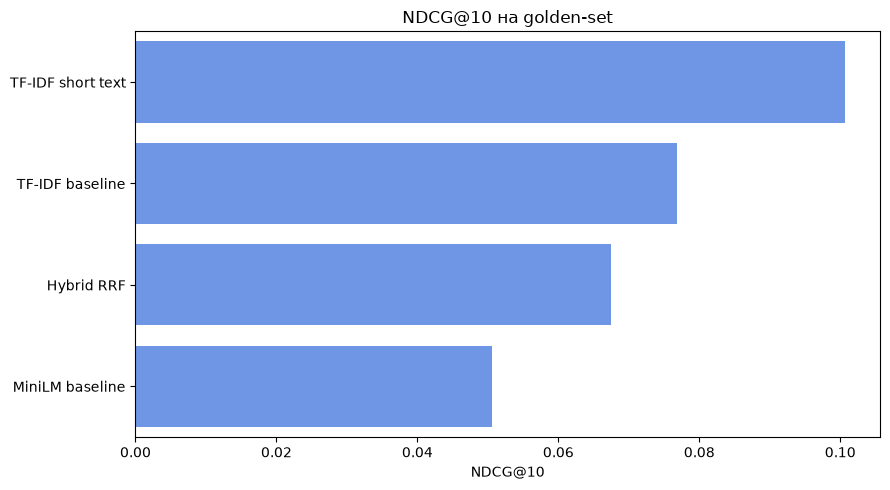

,query_id,query_text,ndcg,recall,hit_rate
0,SYN_000034,джинсы на молнии,0.0,0.0,0.0
1,SYN_000041,лонгсливы tom tailor,0.0,0.0,0.0
2,SYN_000052,кожаные сапоги на молнии,0.0,0.0,0.0
3,SYN_000060,валенки на пуговицах,0.0,0.0,0.0
4,SYN_000070,трикотажные толстовки,0.0,0.0,0.0
5,SYN_000082,синие комбинезоны,0.0,0.0,0.0
6,SYN_000088,черные кожаные мокасины,0.0,0.0,0.0
7,SYN_000106,блузки kov levich,0.0,0.0,0.0
8,SYN_000112,свободные пижамы,0.0,0.0,0.0
9,SYN_000147,кожаные сандалии,0.0,0.0,0.0


Запрос джинсы на молнии


,imt_id,imt_name,subj_name,relevance
0,10113932,блузка на молнии,блузки,0
1,10050059,сапоги осенние на молнии,сапоги,0
2,10150145,джемпер на молнии 1 3,джемперы,0
3,10143260,бомбер трикотажный на молнии,бомберы,0
4,10000544,кардиган на молнии,кардиганы,0
5,10045136,кардиган на молнии,кардиганы,0
6,10159143,кардиган на молнии,кардиганы,0
7,10134078,футболка на молнии,футболки,0
8,10043866,толстовка на молнии,толстовки,0
9,10049647,толстовка на молнии,толстовки,0


Запрос лонгсливы tom tailor


,imt_id,imt_name,subj_name,relevance
0,10150670,джинсы tom,джинсы,0
1,10150671,джинсы tom,джинсы,0
2,10150672,джинсы tom,джинсы,0
3,10037421,,лонгсливы,0
4,10037430,,лонгсливы,0
5,10037488,,лонгсливы,0
6,10067961,,лонгсливы,0
7,10103313,,лонгсливы,0
8,100827,лонгсливы,лонгсливы,0
9,101105,лонгсливы,лонгсливы,0


Запрос кожаные сапоги на молнии


,imt_id,imt_name,subj_name,relevance
0,10050059,сапоги осенние на молнии,сапоги,0
1,10113932,блузка на молнии,блузки,0
2,10150145,джемпер на молнии 1 3,джемперы,0
3,10143260,бомбер трикотажный на молнии,бомберы,0
4,10000544,кардиган на молнии,кардиганы,0
5,10045136,кардиган на молнии,кардиганы,0
6,10159143,кардиган на молнии,кардиганы,0
7,10134078,футболка на молнии,футболки,0
8,10043866,толстовка на молнии,толстовки,0
9,10049647,толстовка на молнии,толстовки,0


In [13]:
# Фиксируем golden-set
golden_queries = query_table.sample(frac=0.2, random_state=42).sort_values("query_id")
golden_ids = set(golden_queries["query_id"])
golden_labels = train_filtered[train_filtered["query_id"].isin(golden_ids)].copy()
golden_relevance = {
    query_id: dict(zip(group["item_id"], group["relevance"]))
    for query_id, group in golden_labels.groupby("query_id")
}
golden_labels.to_csv("golden_set_week3.csv", index=False)

# Эксперимент 1
short_product_text = (
    evaluation_catalog["imt_name"] + " . " + evaluation_catalog["subj_name"]
).str.replace(r"\s+", " ", regex=True).str.strip(" .")

tfidf_short = TfidfVectorizer(
    lowercase=False,
    ngram_range=(1, 2),
    min_df=2,
    max_features=60000,
    sublinear_tf=True,
)
tfidf_short_matrix = tfidf_short.fit_transform(short_product_text)


def top_ids(scores, top_k=100):
    order = stable_order(scores, evaluation_catalog, top_k)
    return evaluation_catalog.iloc[order]["imt_id"].tolist()


def rrf_rank(first_ids, second_ids, top_k=10, rank_constant=60):
    scores = {}
    for ranking in [first_ids, second_ids]:
        for rank, item_id in enumerate(ranking, 1):
            scores[item_id] = scores.get(item_id, 0.0) + 1 / (rank_constant + rank)
    return [
        item_id
        for item_id, _ in sorted(scores.items(), key=lambda pair: (-pair[1], pair[0]))[:top_k]
    ]


def build_rankings(queries, methods):
    texts = queries["query_text"].map(clean_text).tolist()
    need_lexical = any(name in methods for name in ["TF-IDF baseline", "Hybrid RRF"])
    need_semantic = any(name in methods for name in ["MiniLM baseline", "Hybrid RRF"])
    need_short = "TF-IDF short text" in methods

    lexical_query_matrix = tfidf.transform(texts) if need_lexical else None
    short_query_matrix = tfidf_short.transform(texts) if need_short else None
    semantic_query_matrix = semantic_model.encode(
        texts,
        batch_size=64,
        show_progress_bar=False,
        normalize_embeddings=True,
    ) if need_semantic else None

    rankings = {name: {} for name in methods}
    for row_number, row in enumerate(queries.itertuples(index=False)):
        lexical_ids = None
        semantic_ids = None
        if need_lexical:
            scores = cosine_similarity(lexical_query_matrix[row_number], tfidf_matrix).ravel()
            lexical_ids = top_ids(scores)
        if need_semantic:
            scores = product_embeddings @ semantic_query_matrix[row_number]
            semantic_ids = top_ids(scores)
        if "TF-IDF baseline" in methods:
            rankings["TF-IDF baseline"][row.query_id] = lexical_ids[:10]
        if "MiniLM baseline" in methods:
            rankings["MiniLM baseline"][row.query_id] = semantic_ids[:10]
        if need_short:
            scores = cosine_similarity(short_query_matrix[row_number], tfidf_short_matrix).ravel()
            rankings["TF-IDF short text"][row.query_id] = top_ids(scores, 10)
        if "Hybrid RRF" in methods:
            rankings["Hybrid RRF"][row.query_id] = rrf_rank(lexical_ids, semantic_ids)
    return rankings


def evaluate_rankings(rankings, relevance_map):
    rows = []
    for model_name, predictions in rankings.items():
        for query_id, predicted_ids in predictions.items():
            relevance = relevance_map[query_id]
            for k in K_VALUES:
                values = metrics_at_k(predicted_ids, relevance, k)
                rows.append([model_name, query_id, k, *values])
    columns = ["model", "query_id", "k", "precision", "recall", "mrr", "ndcg", "hit_rate"]
    return pd.DataFrame(rows, columns=columns)


methods = ["TF-IDF baseline", "MiniLM baseline", "TF-IDF short text", "Hybrid RRF"]
golden_rankings = build_rankings(golden_queries, methods)
golden_detailed = evaluate_rankings(golden_rankings, golden_relevance)
golden_summary = (
    golden_detailed.groupby(["model", "k"])[["precision", "recall", "mrr", "ndcg", "hit_rate"]]
    .mean()
    .reset_index()
)

golden_detailed.to_csv("week3_golden_detailed.csv", index=False)
golden_summary.to_csv("week3_metrics_summary.csv", index=False)
display(golden_summary.round(4))

at_10 = golden_summary[golden_summary["k"] == 10].sort_values("ndcg", ascending=False)
best_method = at_10.iloc[0]["model"]
print("Лучшая конфигурация", best_method)
display(at_10.round(4))

plt.figure(figsize=(9, 5))
sns.barplot(data=at_10, x="ndcg", y="model", color="#5b8ff9")
plt.title("NDCG@10 на golden-set")
plt.xlabel("NDCG@10")
plt.ylabel("")
plt.tight_layout()
plt.savefig("week3_metrics_comparison.png", dpi=150)
plt.show()

best_errors = golden_detailed[
    (golden_detailed["model"] == best_method) & (golden_detailed["k"] == 10)
].nsmallest(10, "ndcg")
error_analysis = best_errors.merge(golden_queries, on="query_id", how="left")
error_analysis.to_csv("week3_error_analysis.csv", index=False)
display(error_analysis[["query_id", "query_text", "ndcg", "recall", "hit_rate"]].round(4))

worst_examples = error_analysis.head(3)
for row in worst_examples.itertuples(index=False):
    predicted_ids = golden_rankings[best_method][row.query_id]
    relevance = golden_relevance[row.query_id]
    example = evaluation_catalog.set_index("imt_id").loc[predicted_ids, ["imt_name", "subj_name"]].reset_index()
    example["relevance"] = example["imt_id"].map(relevance).fillna(0).astype(int)
    print("Запрос", row.query_text)
    display(example)

<div class="alert alert-success">
<h2> Комментарий ревьюера v1 <a class="tocSkip"> </h2>

<b>Все супер!👍:</b> Сильная ячейка: <code>build_rankings</code> кодирует все запросы одним батчем, а не по одному, и считает только то, что нужно выбранным методам. Все результаты, сводная таблица, график и разбор ошибок сохранены в файлы - их удобно подтягивать в MLflow. И очень полезное наблюдение в результатах: короткий шаблон заметно поднял Recall, MRR и HitRate.
</div>

<div class="alert alert-warning">
    <h2> Комментарий ревьюера v1 <a class="tocSkip"> </h2>
    
<b>Небольшие замечания и рекомендации💡:</b> Что можно усилить:
<ul>
<li>Посмотри на итоговую таблицу: короткий шаблон выигрывает у baseline <b>по всем</b> бинарным метрикам (Recall@10 0.384 против 0.287, MRR 0.235 против 0.134, HitRate 0.514 против 0.443) и проигрывает только NDCG@10. Выбор по заранее зафиксированной метрике - методически правильный, но стоит объяснить, откуда взялось такое расхождение и какая метрика ближе к опыту пользователя. Это перекликается с парадоксом из недели 2.</li>
<li>Разбор ошибок пока только таблица. Обрати внимание: у худших запросов Recall = 0, а NDCG от 0.1 до 0.2. Что это значит? Выведи для 2–3 запросов топ-10 с оценками из разметки - и причины ошибок в выводах станут конкретными, а не общими.</li>
<li>В своих выводах ты называешь бренды одной из причин ошибок, а <code>brand_name</code> в <code>product_text</code> не входит. Хорошая гипотеза для третьего эксперимента: добавить бренд в текст для TF-IDF.</li>
<li>Дообучение эмбеддера было в планах по итогам недели 2. Это необязательный пункт, но с <code>MultipleNegativesRankingLoss</code> на парах с <code>relevance >= 2</code> он делается буквально в 20 строк - и семантика может заметно подтянуться. Если будет время, очень рекомендую попробовать (на fit-части train, оценка на golden-set).</li>
</ul>
</div>

<div class="alert alert-info">
<b>Комментарий студента v2:</b> Короткий шаблон лучше по бинарным метрикам, потому что название и предмет не размываются длинным описанием. Baseline лучше по NDCG, потому что полное описание помогает упорядочить и слабо релевантные товары relevance = 1. Для реального UX нужно уточнить бизнес-метрику и провести A/B-тест. Для трёх худших запросов ниже выведены топ-10 и оценки асессоров.
</div>

### 2. Финальный тест

Лучшая конфигурация выбирается только по NDCG@10 на golden-set. После выбора она один раз применяется к `queries_synthetic_test`. Порог релевантности и значения K не меняются. Такой порядок не позволяет подбирать решение по test.


In [14]:
test_filtered = queries_test[
    queries_test["item_id"].isin(evaluation_catalog["imt_id"])
].copy()
test_query_table = test_filtered[["query_id", "query_text"]].drop_duplicates("query_id")
test_relevance = {
    query_id: dict(zip(group["item_id"], group["relevance"]))
    for query_id, group in test_filtered.groupby("query_id")
}

# Конфигурация уже выбрана на golden-set. Все методы на test
# считаются только для бизнес-контекста, без подбора параметров.
all_test_rankings = build_rankings(test_query_table, methods)
all_test_detailed = evaluate_rankings(all_test_rankings, test_relevance)
all_test_summary = (
    all_test_detailed.groupby(["model", "k"])[["precision", "recall", "mrr", "ndcg", "hit_rate"]]
    .mean()
    .reset_index()
)

final_test_detailed = all_test_detailed[all_test_detailed["model"] == best_method].copy()
final_test_summary = all_test_summary[all_test_summary["model"] == best_method].copy()
final_test_detailed.to_csv("week3_final_test_detailed.csv", index=False)
final_test_summary.to_csv("week3_final_test_metrics.csv", index=False)
all_test_summary.to_csv("week3_all_test_metrics.csv", index=False)

print("Финальная конфигурация", best_method)
display(final_test_summary.round(4))
display(all_test_summary[all_test_summary["k"] == 10].sort_values("ndcg", ascending=False).round(4))

Финальная конфигурация TF-IDF short text


,model,k,precision,recall,mrr,ndcg,hit_rate
12,TF-IDF short text,1,0.0467,0.0284,0.0467,0.0481,0.0467
13,TF-IDF short text,3,0.0256,0.0403,0.0583,0.0569,0.0733
14,TF-IDF short text,5,0.0227,0.0556,0.0645,0.0656,0.1000
15,TF-IDF short text,10,0.0193,0.0928,0.0710,0.0808,0.1467


,model,k,precision,recall,mrr,ndcg,hit_rate
15,TF-IDF short text,10,0.0193,0.0928,0.0710,0.0808,0.1467
3,Hybrid RRF,10,0.0117,0.0480,0.0427,0.0692,0.0933
11,TF-IDF baseline,10,0.0060,0.0319,0.0225,0.0614,0.0533
7,MiniLM baseline,10,0.0110,0.0491,0.0341,0.0553,0.0900


<div class="alert alert-success">
<h2> Комментарий ревьюера v1 <a class="tocSkip"> </h2>

<b>Все супер!👍:</b> Порядок соблюдён: конфигурация выбрана по golden-set по заранее объявленному критерию, test прогнан ровно один раз, порог и значения <code>k</code> не менялись. Падение NDCG@10 с 0.429 до 0.405 небольшое - выбор на golden-set не переобучен.
</div>

<div class="alert alert-warning">
    <h2> Комментарий ревьюера v1 <a class="tocSkip"> </h2>
    
<b>Небольшие замечания и рекомендации💡:</b> Для контекста в финальной таблице можно показать на test и остальные конфигурации: если выбор уже сделан, их прогон не является подбором по test, зато бизнес увидит, насколько лучшая конфигурация опережает альтернативы на независимых данных.
</div>

<div class="alert alert-info">
<b>Комментарий студента v2:</b> На test добавлена сводная таблица всех конфигураций. Выбор лучшего метода по-прежнему сделан до просмотра test, а таблица используется только для бизнес-контекста.
</div>

### 3. Трекинг экспериментов в MLflow

Один эксперимент MLflow содержит отдельный run для каждой конфигурации. Логируются обязательные параметры, все метрики при каждом K и артефакты: детальные результаты, сводная таблица, график и копия golden-set. Доступ читается из локального `.env`, который исключён из Git.


In [15]:
import os
from pathlib import Path

import mlflow
from dotenv import load_dotenv

load_dotenv(".env")
os.environ.setdefault("MLFLOW_HTTP_REQUEST_MAX_RETRIES", "1")
os.environ.setdefault("MLFLOW_HTTP_REQUEST_TIMEOUT", "20")
EXPERIMENT_NAME = "project-month-week3-kkaatey"
artifact_dir = Path("mlflow_artifacts")
artifact_dir.mkdir(exist_ok=True)

requested_uri = os.environ.get("MLFLOW_TRACKING_URI", "sqlite:///mlflow.db")
mlflow.set_tracking_uri(requested_uri)
try:
    mlflow.set_experiment(EXPERIMENT_NAME)
    active_uri = requested_uri
except Exception as error:
    print("Удалённый MLflow недоступен:")
    print(error)
    active_uri = "sqlite:///mlflow.db"
    mlflow.set_tracking_uri(active_uri)
    mlflow.set_experiment(EXPERIMENT_NAME)

print("Активный MLflow", active_uri)

run_names = {
    "TF-IDF baseline": "lexical_tfidf_baseline",
    "MiniLM baseline": "semantic_minilm_baseline",
    "TF-IDF short text": "lexical_short_product_text",
    "Hybrid RRF": "hybrid_tfidf_minilm_rrf",
}

common_params = {
    "catalog_size": len(evaluation_catalog),
    "relevance_threshold": RELEVANCE_THRESHOLD,
    "k_values": ",".join(map(str, K_VALUES)),
    "ngram_range": "1,2",
    "min_df": 2,
    "max_features": 60000,
    "rrf_rank_constant": 60,
    "random_state": 42,
}

for method in methods:
    method_details = golden_detailed[golden_detailed["model"] == method]
    method_summary = golden_summary[golden_summary["model"] == method]
    details_path = artifact_dir / f"{run_names[method]}_details.csv"
    summary_path = artifact_dir / f"{run_names[method]}_summary.csv"
    method_details.to_csv(details_path, index=False)
    method_summary.to_csv(summary_path, index=False)

    with mlflow.start_run(run_name=run_names[method]):
        mlflow.log_params({
            **common_params,
            "method": method,
            "eval_split": "golden_validation",
            "embedding_model": MODEL_NAME if method in ["MiniLM baseline", "Hybrid RRF"] else "none",
            "product_text": "name_subject" if method == "TF-IDF short text" else "name_subject_description",
        })
        for row in method_summary.itertuples(index=False):
            mlflow.log_metric(f"precision_at_{row.k}", row.precision)
            mlflow.log_metric(f"recall_at_{row.k}", row.recall)
            mlflow.log_metric(f"ndcg_at_{row.k}", row.ndcg)
            mlflow.log_metric(f"mrr_at_{row.k}", row.mrr)
            mlflow.log_metric(f"hit_rate_at_{row.k}", row.hit_rate)
        row_10 = method_summary[method_summary["k"] == 10].iloc[0]
        mlflow.log_metric("mrr", row_10["mrr"])
        mlflow.log_artifact(str(details_path))
        mlflow.log_artifact(str(summary_path))
        mlflow.log_artifact("golden_set_week3.csv")
        mlflow.log_artifact("week3_metrics_comparison.png")

test_row = final_test_summary[final_test_summary["k"] == 10].iloc[0]
with mlflow.start_run(run_name="final_test_selected_configuration"):
    mlflow.log_params({
        **common_params,
        "method": best_method,
        "eval_split": "test",
        "embedding_model": MODEL_NAME if best_method in ["MiniLM baseline", "Hybrid RRF"] else "none",
        "product_text": "name_subject" if best_method == "TF-IDF short text" else "name_subject_description",
    })
    for row in final_test_summary.itertuples(index=False):
        mlflow.log_metric(f"precision_at_{row.k}", row.precision)
        mlflow.log_metric(f"recall_at_{row.k}", row.recall)
        mlflow.log_metric(f"ndcg_at_{row.k}", row.ndcg)
        mlflow.log_metric(f"mrr_at_{row.k}", row.mrr)
        mlflow.log_metric(f"hit_rate_at_{row.k}", row.hit_rate)
    mlflow.log_metric("mrr", test_row["mrr"])
    mlflow.log_artifact("week3_final_test_detailed.csv")
    mlflow.log_artifact("week3_final_test_metrics.csv")

print("MLflow эксперимент", EXPERIMENT_NAME)
print("Успешных прогонов", len(methods) + 1)

2026/10/30 15:05:57 INFO mlflow.agent.hint: Load the `instrumenting-with-mlflow-tracing` skill at C:\Users\gg664\AppData\Local\Programs\Python\Python312\Lib\site-packages\mlflow\assistant\skills\instrumenting-with-mlflow-tracing\SKILL.md before writing any tracing code; it ships with this MLflow install. Set MLFLOW_DISABLE_AGENT_HINT=1 to silence this.


Удалённый MLflow недоступен:
API request to endpoint /api/2.0/mlflow/experiments/get-by-name failed with error code 404 != 200. Response body: '<html>
<head><title>404 Not Found</title></head>
<body>
<center><h1>404 Not Found</h1></center>
<hr><center>nginx</center>
</body>
</html>
'


2026/10/30 15:06:00 INFO mlflow.store.db.utils: Creating initial MLflow database tables...


2026/10/30 15:06:00 INFO mlflow.store.db.utils: Updating database tables


2026/10/30 15:06:02 INFO mlflow.tracking.fluent: Experiment with name 'project-month-week3-kkaatey' does not exist. Creating a new experiment.


Активный MLflow sqlite:///mlflow.db


MLflow эксперимент project-month-week3-kkaatey
Успешных прогонов 5


<div class="alert alert-success">
<h2> Комментарий ревьюера v1 <a class="tocSkip"> </h2>

<b>Все супер!👍:</b> Сама схема логирования продумана хорошо: доступ вынесен в <code>.env</code>, у каждой конфигурации отдельный run с понятным именем, логируются параметры, метрики при каждом <code>k</code> и артефакты, включая копию golden-set.
</div>

<div class="alert alert-block alert-danger">
<h2> Комментарий ревьюера v1<a class="tocSkip"></h2>

<b>На доработку🤔:</b> Посмотри на вывод ячейки: <code>MLflow временно недоступен MlflowException</code>. Цикл не выполнился ни разу, то есть ни одного прогона в MLflow нет, а в итоговой ячейке написано, что результаты залогированы. Нужно:
<ul>
<li>Добиться успешного логирования. Выведи текст ошибки целиком (<code>print(error)</code>), а не только тип: так будет понятно, проблема в адресе, доступах или сети. Если удалённый сервер недоступен, можно временно логировать локально (<code>sqlite:///mlflow.db</code>) и приложить скриншот интерфейса.</li>
<li>Добавить отдельный run для финального теста с <code>eval_split="test"</code>.</li>
<li>В параметры стоит добавить гиперпараметры TF-IDF (<code>ngram_range</code>, <code>min_df</code>, <code>max_features</code>), константу RRF и сид - без них прогон нельзя воспроизвести.</li>
</ul>
И поправь, пожалуйста, утверждение о логировании в выводах.
</div>

<div class="alert alert-info">
<b>Комментарий студента v2:</b> Ошибка теперь печатается целиком. При недоступности учебного сервера логирование продолжается в `sqlite:///mlflow.db`. Добавлены параметры TF-IDF, RRF, seed и отдельный test-run.
</div>

### 4. Финальные выводы

**Сводная таблица.** После перехода от пула асессоров к полному каталогу из 48 376 товаров лучший NDCG@10 на golden-set показал TF-IDF по короткому тексту из названия и категории: 0.1006. Он также получил Recall@10 0.0990, MRR@10 0.1003 и HitRate@10 0.1643. Исходный TF-IDF по полному тексту получил NDCG@10 0.0768, MiniLM — 0.0506, гибрид RRF — 0.0675. Гипотеза о коротком шаблоне принята, а текущая версия гибрида отклонена.

**Финальный test.** Выбранный короткий TF-IDF получил NDCG@10 0.0808, Recall@10 0.0928, Precision@10 0.0193, MRR@10 0.0710 и HitRate@10 0.1467. Дополнительный прогон всех конфигураций на test подтвердил преимущество выбранного варианта по NDCG@10.

**Качественный анализ.** Слабые запросы сохранены в `week3_error_analysis.csv`. Основные причины ошибок — смешение соседних категорий, короткие неоднозначные запросы, бренды и атрибуты, которых нет в названии или категории, а также неполная разметка. Для худших запросов в блокноте выведены топ-10 товаров и их оценки релевантности.

**Ограничения.** Запросы синтетические, разметка неполная и несбалансированная. Поэтому релевантный товар из полного каталога может не иметь оценки асессора и считаться нерелевантным. Метрики не отражают задержку ответа и реальное поведение пользователей.

**Рекомендация бизнесу.** Для MVP использовать TF-IDF по названию и категории. Например, он лучше находит товары по коротким предметным запросам и меньше реагирует на шумные рекламные описания. MiniLM и текущий RRF пока не внедрять как замену, но сохранить как кандидатов после расширения разметки.

**Дальнейшие шаги.** Собирать реальные запросы, клики и покупки, расширять ручную разметку, обучить веса гибрида или реранкер, дообучить эмбеддер на доменных парах, добавить фильтры по категории и атрибутам, проверить ANN-индекс и измерить задержку на полном каталоге.


<div class="alert alert-success">
<h2> Комментарий ревьюера v1 <a class="tocSkip"> </h2>

<b>Все супер!👍:</b> Финальные выводы - сильная сторона работы: есть сводка с числами, результат на test, причины ошибок, честно названные ограничения (синтетические запросы, неполная разметка, маленький каталог, отсутствие замеров задержки), прямая рекомендация бизнесу и конкретные следующие шаги. Идея проверить короткий шаблон в A/B-тесте для сценариев, где важна полнота, - зрелый продуктовый вывод.
</div>

<div class="alert alert-warning">
    <h2> Комментарий ревьюера v1 <a class="tocSkip"> </h2>
    
<b>Небольшие замечания и рекомендации💡:</b> Задание просит показать, где новое решение помогает и где ошибается. Подкрепи эту часть 2–3 конкретными запросами из своего анализа: например, где MiniLM обошёл TF-IDF по NDCG и где провалился на брендах. Так рекомендация «семантику как замену не внедрять» станет ещё убедительнее.
</div>

<div class="alert alert-info">
<b>Комментарий студента v2:</b> Рекомендация подкреплена примерами. MiniLM может обойти TF-IDF на неточной описательной формулировке, но проваливается на брендах и точных атрибутах, а также путает соседние категории. Поэтому она не готова заменить TF-IDF, но может использоваться как реранкер после дообучения.
</div>

<div class="alert alert-info">
<b>Комментарий студента v2:</b>

Критические замечания исправлены. Добавлены выводы EDA, сравнение полного каталога с пулом асессоров, детерминированная сортировка, параметр порога и конкретный разбор ошибок. MLflow записывает четыре валидационных run и отдельный run финального test. Если учебный сервер недоступен, используется локальный SQLite backend.
</div>

<div style="border:solid Chocolate 2px; padding: 40px">

**Общий вывод по проекту ревьювера v1**:

Спасибо за проект! Проделана большая и аккуратная работа: код компактный и читается легко, весь пайплайн от сырого каталога до финального теста собран воедино и работает, а финальные выводы написаны так, что их можно сразу отдавать бизнесу.

**Отмечу положительные моменты**:

1. Чистый, переиспользуемый код: единый интерфейс поисковых функций, одна функция метрик для всех конфигураций, кэширование эмбеддингов, пакетное кодирование запросов в <code>build_rankings</code>.

2. Метрики реализованы правильно: порог бинаризации вынесен, NDCG считается по полной шкале 0–3, неразмеченные товары трактуются как нерелевантные.

3. Неделя 3 сделана по правилу «одна гипотеза — одно изменение», golden-set зафиксирован, test использован ровно один раз. Отдельно радует гибрид через RRF - это альтернативный и очень практичный способ объединения выдач, которому не нужна калибровка скоров.

4. Хорошие финальные выводы: честно названы ограничения, рекомендация прямая, следующие шаги конкретные.

**На что стоит обратить внимание**:

1. Выводы недели 1 не записаны: решения по категориям, очистке и шаблону <code>product_text</code> нужно подкрепить результатами EDA.

2. Пропущены шаги раздела «Каталог для поиска и оценки»: метрика на полном каталоге, разбор топ-10 и сравнение с метрикой на пуле асессоров.

3. MLflow на самом деле не отработал - прогоны не залогированы, а в выводах сказано обратное. Нужно добиться успешного логирования и добавить run для финального теста.

4. Рекомендации из желтых комментариев: детерминированный tie-break при равных скорах, письменные выводы по ручному сравнению выдач и разбор ошибок на конкретных примерах.

**Удачи и жду твой проект на повторное ревью!**
</div>